# 02 · USDA ERS meat price spreads

**Milestone 1, item 1.3** · see `docs/MILESTONES.md`

## What we're looking for

Notebook 01 showed *how much* beef, pork and chicken cost. This notebook gets the data
that shows *who gets the money*. For every pound of meat sold at retail, USDA's Economic
Research Service (ERS) estimates its value at three stages:

| Stage | What it means |
|---|---|
| **Farm value** | What the rancher or hog farmer is paid for the animal |
| **Wholesale value** | What the meatpacker gets for the cuts it sells to stores |
| **Retail value** | What shoppers pay at the store |

The gaps between them are the **price spreads**: farm-to-wholesale (roughly the packer's
share) and wholesale-to-retail (roughly the grocery store's share). If beef's price rose
63% since 2015, the spreads tell us whether that money went to ranchers or stayed with
packers and stores.

**This notebook has two parts.** Part 1 (this run) downloads the files and takes an
inventory of what's in them. ERS splits the data across files with slightly different
names for the same things, so before combining anything we'll review the inventory
together and agree on which items to keep. Part 2 then combines them.

**Steps (Part 1)**
1. Setup
2. Which files we need, and why
3. Download and save them, untouched, to `data/raw/`
4. Load them and put them in one consistent shape
5. Inventory: every data item, its units, and the months it covers

## Step 1 · Setup

No API key is needed: ERS publishes these as plain file downloads.

In [7]:
from datetime import date
from pathlib import Path

import pandas as pd
import requests
from dotenv import find_dotenv

env_path = find_dotenv()
PROJECT_ROOT = Path(env_path).parent if env_path else Path.cwd().parent
RAW_DIR = PROJECT_ROOT / "data" / "raw" / f"ers_{date.today():%Y%m%d}"
RAW_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_rows", 200)
pd.set_option("display.max_colwidth", 80)

print("Project root:", PROJECT_ROOT)
print("Saving to:", RAW_DIR.relative_to(PROJECT_ROOT))

Project root: B:\_Dev\Python\meat-prices
Saving to: data\raw\ers_20261026


## Step 2 · Which files we need, and why

The [ERS Meat Price Spreads page](https://www.ers.usda.gov/data-products/meat-price-spreads)
offers five files. We need four of them, because the history and the recent months live
in different files:

| File | Covers | Why we need it |
|---|---|---|
| **Historical monthly price spreads** (beef, pork, broilers) | 1970 to early 2026 (last updated Feb 2026) | The long history, including 2015–2019 |
| **Choice beef values and spreads** | Last 24 months (Oct 2024 to Sep 2026) | Brings beef up to date |
| **Pork values and spreads** | Last 24 months | Brings pork up to date |
| **Summary of retail prices and price spreads** | Last 24 months | The only current file with the **chicken (broiler)** spread |

We skip the fifth file (retail prices by cut): we already have retail prices from BLS.

We download the **CSV** versions rather than Excel. They're already in a long, tidy
layout (one row per item per month), which saves a lot of reshaping.

**About chicken:** ERS reports only the wholesale-to-retail spread for chicken, not a
farm value. Most chickens are raised under contract for the processing companies rather
than sold at a farm price, so there's no clean "farm value" to measure. Beef and pork
get the full farm → wholesale → retail breakdown; chicken gets wholesale → retail only.

In [8]:
ERS_FILES = {
    "historical": "https://www.ers.usda.gov/media/5028/historical-monthly-price-spread-data-for-beef-pork-broilers.csv",
    "beef_recent": "https://www.ers.usda.gov/media/5020/choice-beef-values-and-spreads-and-the-all-fresh-retail-value.csv",
    "pork_recent": "https://www.ers.usda.gov/media/5026/pork-values-and-spreads.csv",
    "summary_recent": "https://www.ers.usda.gov/media/5025/summary-of-retail-prices-and-price-spreads.csv",
}

pd.Series(ERS_FILES, name="url").to_frame()

,url
historical,https://www.ers.usda.gov/media/5028/historical-monthly-price-spread-data-for...
beef_recent,https://www.ers.usda.gov/media/5020/choice-beef-values-and-spreads-and-the-a...
pork_recent,https://www.ers.usda.gov/media/5026/pork-values-and-spreads.csv
summary_recent,https://www.ers.usda.gov/media/5025/summary-of-retail-prices-and-price-sprea...


## Step 3 · Download and save

Same rule as notebook 01: save exactly what ERS sent before changing anything. Each
download goes into a dated folder, so a later re-download never overwrites this one.

Some government sites reject requests that don't look like they come from a browser, so
we send a normal browser `User-Agent` header. If a download still fails, the error says
which file, and you can download it by hand from the ERS page into the same folder.

In [9]:
HEADERS = {"User-Agent": "Mozilla/5.0 (meat-prices portfolio project; data download)"}

saved = {}
for name, url in ERS_FILES.items():
    resp = requests.get(url, headers=HEADERS, timeout=60)
    resp.raise_for_status()
    path = RAW_DIR / f"{name}.csv"
    path.write_bytes(resp.content)
    saved[name] = path
    print(f"{name:15} {len(resp.content):>10,} bytes  ->  {path.name}")

historical       1,170,589 bytes  ->  historical.csv
beef_recent         50,639 bytes  ->  beef_recent.csv
pork_recent         45,266 bytes  ->  pork_recent.csv
summary_recent      41,001 bytes  ->  summary_recent.csv


### How to read it
One line per file with its size. The historical file should be by far the largest
(about 1 MB); the three recent files are small (roughly 40–50 KB each).

## Step 4 · Load and standardize

The four files are almost, but not quite, the same shape:

| File | Month columns |
|---|---|
| Historical | `Year`, `Month`, `Month-number` |
| Summary | `Year`, `Month`, `Month_Number` |
| Beef and pork | `Year`, `Period`, `Period_Number` |

The beef and pork files also mix **annual** and **quarterly** rows in with the monthly
ones. Their `Period_Number` tells them apart: 1–12 are months, 13–16 are quarters, and
17 is the annual average. We keep months only.

ERS also writes values of 1,000 or more with a thousands comma (`1,011.3`). Python
doesn't read that as a number, so the function strips the comma first. (The first run
missed this: beef retail value, which passed $10.00/lb in late 2025, appeared to have
10 missing months. They weren't missing; they just had commas.)

The function below handles all three layouts and returns the same columns for every file:
`date`, `data_item`, `value`, `units`, `source_file`.

In [10]:
def load_ers(path, source_name):
    """Load an ERS price-spread CSV and return monthly rows in one standard shape."""
    df = pd.read_csv(path, encoding="utf-8-sig")
    df.columns = [col.strip() for col in df.columns]

    # Find whichever month-number column this file uses
    month_col = next(col for col in ["Month-number", "Month_Number", "Period_Number"] if col in df.columns)

    df["month_num"] = pd.to_numeric(df[month_col], errors="coerce")
    df = df[df["month_num"].between(1, 12)].copy()   # drops quarters (13-16) and annual (17)

    df["date"] = pd.to_datetime(dict(year=df["Year"].astype(int), month=df["month_num"].astype(int), day=1))
    # Values of 1,000 or more come with a thousands comma ("1,011.3"); remove it first,
    # otherwise to_numeric turns those values into missing (NaN).
    df["value"] = pd.to_numeric(df["Value"].astype(str).str.replace(",", "", regex=False), errors="coerce")

    out = df.rename(columns={"Data_Item": "data_item", "Units": "units"})
    out["data_item"] = out["data_item"].str.strip()
    out["source_file"] = source_name
    return out[["date", "data_item", "value", "units", "source_file"]]

frames = {name: load_ers(path, name) for name, path in saved.items()}

for name, df in frames.items():
    print(f"{name:15} {len(df):>7,} monthly rows | {df['data_item'].nunique():>3} items | "
          f"{df['date'].min():%Y-%m} to {df['date'].max():%Y-%m}")

historical       13,080 monthly rows |  20 items | 1970-01 to 2025-12
beef_recent         312 monthly rows |  13 items | 2024-10 to 2026-09
pork_recent         288 monthly rows |  12 items | 2024-10 to 2026-09
summary_recent      516 monthly rows |  38 items | 2024-10 to 2026-09


### How to read it
For each file: how many monthly rows it has, how many different data items, and the
first and last month.

**What we're looking for:**
- The historical file should start in **1970**. Its **last month** tells us how far the
  history reaches (expected around late 2025 or early 2026, since it was last updated in
  February 2026).
- The three recent files should run from about **October 2024 to September 2026**.
- Where the two overlap (late 2024 to early 2026), we can check that ERS reports the
  same values in both. We'll do that in Part 2.

## Step 5 · Inventory of data items

**What we're looking for:** the exact name of every data item in each file, with its
units and date range. ERS sometimes names the same measure differently in different files
(for example "byproduct value" in one and "byproduct allowance" in another), so we need to
see the names side by side before we can match them up.

We only look at months from 2015 onward, the period this project covers (D3).

In [11]:
inventory = (
    pd.concat(frames.values())
    .query("date >= '2015-01-01'")
    .dropna(subset=["value"])
    .groupby(["source_file", "data_item", "units"])
    .agg(first=("date", "min"), last=("date", "max"), months=("value", "size"))
    .reset_index()
)
inventory["first"] = inventory["first"].dt.strftime("%Y-%m")
inventory["last"] = inventory["last"].dt.strftime("%Y-%m")

inventory[inventory["source_file"] == "historical"]

,source_file,data_item,units,first,last,months
13,historical,All fresh beef retail value,Cents per pound of retail equivalent,2015-01,2025-12,132
14,historical,Choice beef byproduct value,Cents per pound of retail equivalent,2015-01,2025-12,132
15,historical,Choice beef farm to retail price spread,Cents per pound of retail equivalent,2015-01,2025-12,132
16,historical,Choice beef farm to wholesale price spread,Cents per pound of retail equivalent,2015-01,2025-12,132
17,historical,Choice beef gross farm value,Cents per pound of retail equivalent,2015-01,2025-12,132
18,historical,Choice beef net farm value,Cents per pound of retail equivalent,2015-01,2025-12,132
19,historical,Choice beef retail value,Cents per pound of retail equivalent,2015-01,2025-12,132
20,historical,Choice beef wholesale to retail price spread,Cents per pound of retail equivalent,2015-01,2025-12,132
21,historical,Choice beef wholesale value,Cents per pound of retail equivalent,2015-01,2025-12,132
22,historical,Pork Wholesale to retail price spread,Cents per pound of retail equivalent,2015-01,2025-12,132


### How to read it
Every data item in the **historical** file from 2015 on: its units (mostly *cents per
pound of retail equivalent*, meaning the value is expressed per pound of meat as sold at
the store), and the first and last month it has data.

In [12]:
inventory[inventory["source_file"] != "historical"]

,source_file,data_item,units,first,last,months
0,beef_recent,All-fresh beef retail value,Cents/lb,2024-10,2026-09,24
1,beef_recent,Cattle 5-market steer price,Dollars/cwt,2024-10,2026-09,24
2,beef_recent,Choice beef byproduct allowance,Cents per pound of retail equivalent,2024-10,2026-09,24
3,beef_recent,Choice beef farm-wholesale spread share of retail beef dollar,Percent,2024-10,2026-09,24
4,beef_recent,Choice beef farmers' share of retail beef dollar,Percent,2024-10,2026-09,24
5,beef_recent,Choice beef gross farm value,Cents per pound of retail equivalent,2024-10,2026-09,24
6,beef_recent,Choice beef net farm value,Cents per pound of retail equivalent,2024-10,2026-09,24
7,beef_recent,"Choice beef price spread, farm to retail",Cents per pound of retail equivalent,2024-10,2026-09,24
8,beef_recent,"Choice beef price spread, farm to wholesale",Cents per pound of retail equivalent,2024-10,2026-09,24
9,beef_recent,"Choice beef price spread, wholesale to retail",Cents per pound of retail equivalent,2024-10,2026-09,24


### How to read it
The same inventory for the three **recent** files. The summary file also carries CPI
series and retail prices by cut; we'll only need its broiler (chicken) items.

### What it means
Reviewed together after the first run:
- **Together the files cover our whole period.** The historical file ends in
  **December 2025**; the recent beef and pork files run **October 2024 to September
  2026**. They overlap for 15 months, which lets us check they agree.
- **Same measures, different names.** For example "byproduct value" (historical) vs
  "byproduct allowance" (recent). We'll match names by hand.
- **Chicken appears twice in the historical file** because its units label changed in
  January 2025, from "Cents per retail pound" to "Cents per pound of retail equivalent".
  Part 2 checks whether that's only a relabel or a real change in method.
- **Chicken has a hole.** The summary file only carries the latest 6 months of broiler
  data (April–September 2026), and the historical file stops at December 2025, so
  **January–March 2026 is missing for chicken**. That's longer than the 2-month limit in
  D18, so it stays a gap.
- A first run showed beef retail value with only 14 of 24 recent months. That was a bug
  in our loader (values over 1,000 have a thousands comma), now fixed in Step 4.

---

# Part 2 · Combine into one table

## What we're looking for

One monthly table from **January 2015 to September 2026** with, for each meat, the
three values we agreed to keep (decision D22). "Three values" means the three
stages of the supply chain, the same for each meat, not three data sources:

| Value | Meaning | Meats |
|---|---|---|
| **Retail value** | What shoppers pay | Beef, pork, chicken |
| **Wholesale value** | What the packer (or chicken processor) gets | Beef, pork, chicken |
| **Net farm value** | What the rancher or hog farmer gets, after subtracting hides and other byproducts | Beef, pork |

All in **cents per pound of retail equivalent**: the value per pound of meat as sold in
the store, at each stage.

From those we **calculate** the spreads and shares ourselves, using ERS's definitions:

| Calculated | Formula | Roughly whose share |
|---|---|---|
| Farm-to-wholesale spread | wholesale − net farm | Packer |
| Wholesale-to-retail spread | retail − wholesale | Grocery store |
| Farmer's share | net farm ÷ retail | Rancher / farmer |

**Steps (Part 2)**
6. Map each value to its name in each file
7. Check the historical and recent files agree where they overlap
8. Combine, preferring the newer files
9. Fill in chicken's recent wholesale value
10. Calculate spreads and shares, and check them against ERS's own figures
11. Check the chicken units label change
12. Coverage check
13. Chart: who gets each dollar
14. Save the combined table

## Step 6 · Map each value to its name in each file

This table is the result of reviewing the inventory. Each row says: for this meat and
value, here's the exact item name in the historical file and in the recent file.

Chicken's recent **wholesale** value isn't in any recent file. The summary file has the
retail value and the wholesale-to-retail spread instead, so in Step 9 we work it out as
retail − spread.

In [13]:
ITEM_MAP = [
    # meat,     measure,     historical name,                recent file,      recent name
    ("Beef",    "retail",    "Choice beef retail value",     "beef_recent",    "Choice beef retail value"),
    ("Beef",    "wholesale", "Choice beef wholesale value",  "beef_recent",    "Choice beef wholesale value"),
    ("Beef",    "net_farm",  "Choice beef net farm value",   "beef_recent",    "Choice beef net farm value"),
    ("Pork",    "retail",    "Pork retail value",            "pork_recent",    "Pork retail value"),
    ("Pork",    "wholesale", "Pork wholesale value",         "pork_recent",    "Pork wholesale value"),
    ("Pork",    "net_farm",  "Pork net farm value",          "pork_recent",    "Pork net farm value"),
    ("Chicken", "retail",    "Retail broiler composite",     "summary_recent", "Retail prices or values: retail broiler composite"),
    ("Chicken", "wholesale", "Wholesale broiler composite",  None,             None),
]

def pick(source, item):
    """Return one item from one file as a Series indexed by month (from 2015 on)."""
    df = frames[source]
    s = df[(df["data_item"] == item) & (df["date"] >= "2015-01-01")].set_index("date")["value"]
    return s.dropna().sort_index()

pd.DataFrame(ITEM_MAP, columns=["meat", "measure", "historical name", "recent file", "recent name"])

,meat,measure,historical name,recent file,recent name
0,Beef,retail,Choice beef retail value,beef_recent,Choice beef retail value
1,Beef,wholesale,Choice beef wholesale value,beef_recent,Choice beef wholesale value
2,Beef,net_farm,Choice beef net farm value,beef_recent,Choice beef net farm value
3,Pork,retail,Pork retail value,pork_recent,Pork retail value
4,Pork,wholesale,Pork wholesale value,pork_recent,Pork wholesale value
5,Pork,net_farm,Pork net farm value,pork_recent,Pork net farm value
6,Chicken,retail,Retail broiler composite,summary_recent,Retail prices or values: retail broiler composite
7,Chicken,wholesale,Wholesale broiler composite,NaN,NaN


## Step 7 · Do the files agree where they overlap?

**What we're looking for:** for the 15 months covered by both the historical and the
recent files (October 2024 to December 2025), the values should be the same. If they
differ a lot, ERS revised its numbers, and we'd need to decide which to trust.

In [14]:
overlap_rows = []
for meat, measure, hist_name, recent_file, recent_name in ITEM_MAP:
    if recent_file is None:
        continue
    h = pick("historical", hist_name)
    r = pick(recent_file, recent_name)
    both = pd.concat([h, r], axis=1, keys=["historical", "recent"]).dropna()
    diff = (both["historical"] - both["recent"]).abs()
    overlap_rows.append({
        "meat": meat, "measure": measure, "months_overlapping": len(both),
        "largest_difference_cents": round(diff.max(), 2) if len(both) else None,
    })

pd.DataFrame(overlap_rows)

,meat,measure,months_overlapping,largest_difference_cents
0,Beef,retail,15,0.05
1,Beef,wholesale,15,0.05
2,Beef,net_farm,15,0.05
3,Pork,retail,15,0.05
4,Pork,wholesale,15,0.05
5,Pork,net_farm,15,0.05
6,Chicken,retail,0,NaN


### How to read it
- **months_overlapping:** months that appear in both files (15 expected for beef and pork).
- **largest_difference_cents:** the biggest gap between the two files' values, in cents
  per pound, across those months.

Chicken isn't listed: its recent data starts in April 2026, after the historical file
ends, so there's no overlap to compare.

### What it means
The largest difference is **0.05 cents per pound**, which is just rounding: the
historical file stores more decimal places than the recent files. **The two files agree**,
so joining them won't create a jump where one file hands over to the other.

## Step 8 · Combine, preferring the newer files

For each meat and value we take the historical series and lay the recent series over it.
Where both have a month, we use the **recent** file, because it was updated more recently
(October 2026 vs February 2026) and would include any ERS revisions. Step 7 showed the
choice makes no real difference, but it's the right default. A `source` column records
where every number came from.

In [15]:
pieces = []
for meat, measure, hist_name, recent_file, recent_name in ITEM_MAP:
    h = pick("historical", hist_name).to_frame("value").assign(source="historical")
    if recent_file is not None:
        r = pick(recent_file, recent_name).to_frame("value").assign(source=recent_file)
        h = h[~h.index.isin(r.index)]          # recent wins where both exist
        combined = pd.concat([h, r])
    else:
        combined = h
    pieces.append(combined.assign(meat=meat, measure=measure))

values = pd.concat(pieces).rename_axis("date").reset_index().sort_values(["meat", "measure", "date"])
values.groupby(["meat", "measure", "source"])["date"].agg(["min", "max", "count"])

min        max  count
meat    measure   source                                     
Beef    net_farm  beef_recent    2024-10-01 2026-09-01     24
                  historical     2015-01-01 2024-09-01    117
        retail    beef_recent    2024-10-01 2026-09-01     24
                  historical     2015-01-01 2024-09-01    117
        wholesale beef_recent    2024-10-01 2026-09-01     24
                  historical     2015-01-01 2024-09-01    117
Chicken retail    historical     2015-01-01 2025-12-01    132
                  summary_recent 2026-04-01 2026-09-01      6
        wholesale historical     2015-01-01 2025-12-01    132
Pork    net_farm  historical     2015-01-01 2024-09-01    117
                  pork_recent    2024-10-01 2026-09-01     24
        retail    historical     2015-01-01 2024-09-01    117
                  pork_recent    2024-10-01 2026-09-01     24
        wholesale historical     2015-01-01 2024-09-01    117
                  pork_recent    2024-10-01 2026-09-01     24

### How to read it
For each meat and value, which file supplied which months. Beef and pork should come
from `historical` through September 2024 and from their recent file from October 2024 on.
Chicken retail comes from `historical` through December 2025 and `summary_recent` from
April 2026; chicken wholesale is historical only until Step 9 fills in the recent months.

## Step 9 · Chicken's recent wholesale value

For April–September 2026, the summary file gives chicken's retail value and its
wholesale-to-retail spread. Since spread = retail − wholesale, it follows that:

**wholesale = retail − spread**

We check this works by applying the same formula to the historical file, where all
three are reported, before using it on the recent months.

In [16]:
# Check the formula on historical data, where all three are reported
h_retail = pick("historical", "Retail broiler composite")
h_whole = pick("historical", "Wholesale broiler composite")
h_spread = pick("historical", "Retail-wholesale spread for broiler composite")
check = (h_retail - h_spread - h_whole).abs().max()
print(f"Historical check, largest error: {check:.6f} cents")

# Apply it to the recent months
s_retail = pick("summary_recent", "Retail prices or values: retail broiler composite")
s_spread = pick("summary_recent", "Price spread: wholesale-retail broiler spread")
derived = (s_retail - s_spread).dropna().to_frame("value").assign(
    source="summary_recent (retail - spread)", meat="Chicken", measure="wholesale")

values = pd.concat([values, derived.rename_axis("date").reset_index()]).sort_values(["meat", "measure", "date"])
derived.round(1)

Historical check, largest error: 0.000000 cents


,value,source,meat,measure
date,,,,
2026-04-01,89.4,summary_recent (retail - spread),Chicken,wholesale
2026-05-01,93.9,summary_recent (retail - spread),Chicken,wholesale
2026-06-01,95.0,summary_recent (retail - spread),Chicken,wholesale
2026-07-01,101.5,summary_recent (retail - spread),Chicken,wholesale
2026-08-01,97.1,summary_recent (retail - spread),Chicken,wholesale
2026-09-01,91.2,summary_recent (retail - spread),Chicken,wholesale


### How to read it
- The **historical check** should be essentially zero, meaning retail − spread really
  does equal wholesale in ERS's own data.
- The table shows the six recent months of chicken wholesale value we derived.

## Step 10 · Calculate spreads and shares, and check them against ERS

We turn the table wide (one column per value) and calculate the spreads and the
farmer's share. Then we compare our numbers with the spreads and shares ERS publishes.
If they match, our join and our formulas are both right.

In [17]:
wide = values.pivot_table(index="date", columns=["meat", "measure"], values="value")

calc = {}
for meat in ["Beef", "Pork", "Chicken"]:
    retail = wide[(meat, "retail")]
    wholesale = wide[(meat, "wholesale")]
    calc[(meat, "retail")] = retail
    calc[(meat, "wholesale")] = wholesale
    calc[(meat, "spread_wholesale_to_retail")] = retail - wholesale
    calc[(meat, "store_share_pct")] = (retail - wholesale) / retail * 100
    if (meat, "net_farm") in wide.columns:
        net_farm = wide[(meat, "net_farm")]
        calc[(meat, "net_farm")] = net_farm
        calc[(meat, "spread_farm_to_wholesale")] = wholesale - net_farm
        calc[(meat, "farmer_share_pct")] = net_farm / retail * 100
        calc[(meat, "packer_share_pct")] = (wholesale - net_farm) / retail * 100

spreads = pd.DataFrame(calc)
spreads.columns = pd.MultiIndex.from_tuples(spreads.columns, names=["meat", "measure"])

# Compare with what ERS publishes
ERS_CHECKS = [
    ("Beef", "spread_farm_to_wholesale",   "historical",  "Choice beef farm to wholesale price spread"),
    ("Beef", "spread_wholesale_to_retail", "historical",  "Choice beef wholesale to retail price spread"),
    ("Beef", "spread_farm_to_wholesale",   "beef_recent", "Choice beef price spread, farm to wholesale"),
    ("Beef", "spread_wholesale_to_retail", "beef_recent", "Choice beef price spread, wholesale to retail"),
    ("Beef", "farmer_share_pct",           "beef_recent", "Choice beef farmers' share of retail beef dollar"),
    ("Pork", "spread_farm_to_wholesale",   "historical",  "Pork farm to wholesale price spread"),
    ("Pork", "spread_wholesale_to_retail", "historical",  "Pork Wholesale to retail price spread"),
    ("Pork", "spread_farm_to_wholesale",   "pork_recent", "Pork price spread: farm to wholesale"),
    ("Pork", "spread_wholesale_to_retail", "pork_recent", "Pork price spread: wholesale to retail"),
    ("Pork", "farmer_share_pct",           "pork_recent", "Pork farmers' share of retail value"),
    ("Chicken", "spread_wholesale_to_retail", "historical", "Retail-wholesale spread for broiler composite"),
]

check_rows = []
for meat, measure, source, ers_name in ERS_CHECKS:
    ours = spreads[(meat, measure)]
    theirs = pick(source, ers_name)
    both = pd.concat([ours, theirs], axis=1, keys=["ours", "ers"]).dropna()
    check_rows.append({
        "meat": meat, "measure": measure, "checked_against": source,
        "months": len(both), "largest_difference": round((both["ours"] - both["ers"]).abs().max(), 3),
    })

pd.DataFrame(check_rows)

,meat,measure,checked_against,months,largest_difference
0,Beef,spread_farm_to_wholesale,historical,132,0.059
1,Beef,spread_wholesale_to_retail,historical,132,0.090
2,Beef,spread_farm_to_wholesale,beef_recent,24,0.000
3,Beef,spread_wholesale_to_retail,beef_recent,24,0.000
4,Beef,farmer_share_pct,beef_recent,24,0.049
5,Pork,spread_farm_to_wholesale,historical,132,0.074
6,Pork,spread_wholesale_to_retail,historical,132,0.089
7,Pork,spread_farm_to_wholesale,pork_recent,24,69.000
8,Pork,spread_wholesale_to_retail,pork_recent,24,0.000
9,Pork,farmer_share_pct,pork_recent,24,0.049


### How to read it
One row per check: our calculated spread or share against the figure ERS publishes, the
number of months compared, and the largest difference (cents per pound for spreads,
percentage points for shares).

### What it means
**Ten of the eleven checks match to within 0.1**, which is rounding (ERS publishes one
decimal place). Our formulas match ERS's own definitions, and the combined table agrees
with both source files.

**One check doesn't match: pork farm-to-wholesale in the recent pork file, off by up to
69 cents.** The next step shows why. In short, it's an error in the ERS file, not in our
calculation.

### Investigating the pork mismatch

**What we're looking for:** whether our pork farm-to-wholesale spread is wrong, or ERS's
published figure is. ERS's numbers have to add up: the total farm-to-retail spread should
equal farm-to-wholesale plus wholesale-to-retail. Below are all of ERS's own pork figures
for one month, October 2024, straight from the recent pork file.

In [18]:
pork = frames["pork_recent"]
pork_oct = pork[pork["date"] == pd.Timestamp("2024-10-01")][["data_item", "value", "units"]]
pork_oct

,data_item,value,units
18,Pork retail value,492.00,Cents per pound of retail equivalent
60,Pork wholesale value,186.20,Cents per pound of retail equivalent
102,Pork gross farm value,115.00,Cents per pound of retail equivalent
144,Pork byproduct allowance,8.70,Cents per pound of retail equivalent
186,Pork net farm value,106.30,Cents per pound of retail equivalent
228,Pork price spread: farm to retail,385.70,Cents per pound of retail equivalent
270,Pork price spread: farm to wholesale,16.20,Cents per pound of retail equivalent
312,Pork price spread: wholesale to retail,305.80,Cents per pound of retail equivalent
354,Pork wholesale-retail spread share of retail value,62.20,Percent
396,Pork farm-wholesale spread share of retail value,16.20,Percent


### How to read it
Every value ERS reports for pork in October 2024, in cents per pound unless the units say
percent.

### What it means
- ERS's **farm-to-retail** spread is 385.7 and its **wholesale-to-retail** spread is
  305.8, so farm-to-wholesale should be **385.7 − 305.8 = 79.9 cents**. That's exactly
  what we calculate (wholesale 186.2 − net farm 106.3 = 79.9).
- ERS's published **farm-to-wholesale** figure is **16.2**, which doesn't add up. But
  16.2 is exactly the value of the row **"farm-wholesale spread share of retail value"**,
  which is in *percent* (79.9 ÷ 492.0 = 16.2%).
- The same is true in every recent month: the cents column holds the percent value.

**Conclusion:** in the recent pork file, ERS's "Pork price spread: farm to wholesale"
column contains the percentage share instead of cents per pound. It's mislabeled in the
source file. Our calculated value is consistent with every other figure ERS publishes,
so we keep ours (decision D23). The historical pork file doesn't have this problem
(its check above matches to within 0.1).

This is a good example of why we calculate the spreads ourselves and check them, rather
than copying the published columns.

## Step 11 · Chicken's units label change

**What we're looking for:** in January 2025 ERS changed chicken's units label from
"Cents per retail pound" to "Cents per pound of retail equivalent". If that was only a
relabel, the values should carry on smoothly across December 2024 → January 2025. If ERS
changed its method, we'd expect a jump.

In [19]:
chicken = spreads["Chicken"][["retail", "wholesale"]].loc["2024-07":"2025-06"]
chicken_change = chicken.diff()
pd.concat([chicken.round(1), chicken_change.round(1).add_suffix("_change")], axis=1)

measure,retail,wholesale,retail_change,wholesale_change
date,,,,
2024-07-01,241.1,117.5,NaN,NaN
2024-08-01,244.1,115.1,2.9,-2.4
2024-09-01,246.8,114.0,2.7,-1.1
2024-10-01,244.8,110.1,-2.0,-3.9
2024-11-01,242.3,116.9,-2.4,6.8
2024-12-01,243.4,110.7,1.1,-6.2
2025-01-01,242.7,111.0,-0.7,0.3
2025-02-01,243.1,121.7,0.5,10.7
2025-03-01,245.2,107.7,2.1,-14.0


### How to read it
Six months either side of the label change, with each month's change from the month
before.

### What it means
The change from December 2024 to January 2025 is **small: retail moved less than 1 cent**,
well within its normal month-to-month movement. Wholesale moves more from month to month
throughout, and January 2025 isn't unusual. **It's a relabel, not a change in method**,
so the chicken series can be used as one continuous series.

## Step 12 · Coverage check

**What we're looking for:** every month from January 2015 to September 2026 for beef and
pork. For chicken we expect exactly the known gap, January–March 2026.

In [20]:
all_months = pd.date_range("2015-01-01", spreads.index.max(), freq="MS")
coverage_rows = []
for meat in ["Beef", "Pork", "Chicken"]:
    s = spreads[(meat, "retail")].dropna()
    s_whole = spreads[(meat, "wholesale")].dropna()
    have = s.index.intersection(s_whole.index)
    missing = [d.strftime("%Y-%m") for d in all_months if d not in have]
    coverage_rows.append({"meat": meat, "first": have.min().strftime("%Y-%m"),
                          "last": have.max().strftime("%Y-%m"), "months": len(have),
                          "missing": ", ".join(missing) or "none"})
print("Expected months:", len(all_months))
pd.DataFrame(coverage_rows)

Expected months: 141


,meat,first,last,months,missing
0,Beef,2015-01,2026-09,141,none
1,Pork,2015-01,2026-09,141,none
2,Chicken,2015-01,2026-09,138,"2026-01, 2026-02, 2026-03"


### What it means
Beef and pork are **complete**: all 141 months from January 2015 to September 2026,
including October 2025 (ERS has a value for that month even though BLS doesn't).
Chicken is missing exactly **January–March 2026**, as expected. Per D22 that gap is left
as-is and will be noted on the app's methods page.

## Step 13 · Who gets each retail dollar?

**What we're looking for:** how the retail price splits between the farm, the packer and
the store, and how that split changed over time. This is the first draft of the app's
"Where does each dollar go?" section.

The chart shows each share as a percentage of the retail price, so the three layers for
beef and pork always add up to 100%. Chicken has no farm value, so it shows only the
store's share and the rest (processor and farm combined).

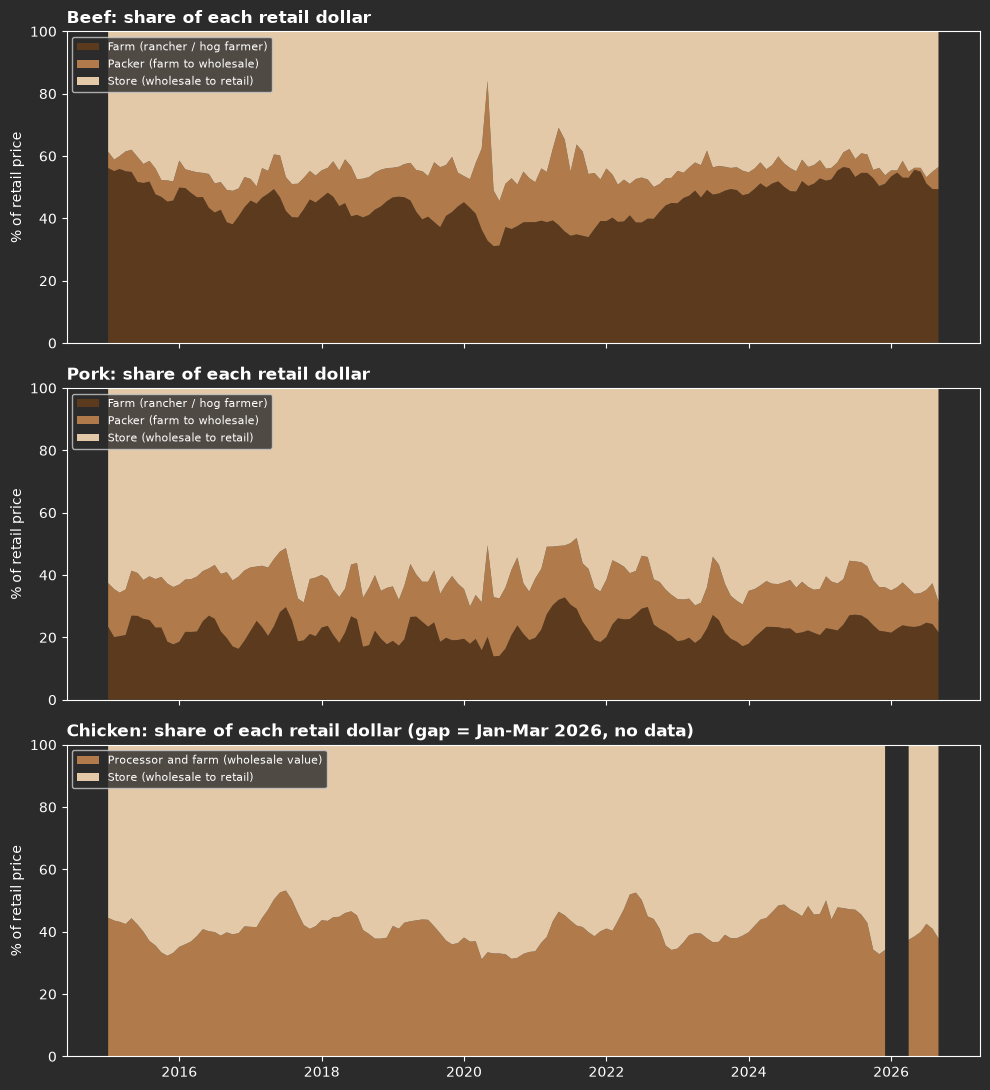

In [21]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 1, figsize=(10, 11), sharex=True)
colors = {"farm": "#5B3A1E", "packer": "#B07A4A", "store": "#E3C9A8"}

for ax, meat in zip(axes[:2], ["Beef", "Pork"]):
    d = spreads[meat]
    ax.stackplot(d.index, d["farmer_share_pct"], d["packer_share_pct"], d["store_share_pct"],
                 labels=["Farm (rancher / hog farmer)", "Packer (farm to wholesale)", "Store (wholesale to retail)"],
                 colors=[colors["farm"], colors["packer"], colors["store"]])
    ax.set_title(f"{meat}: share of each retail dollar", loc="left", fontweight="bold")
    ax.set_ylim(0, 100)
    ax.set_ylabel("% of retail price")
    ax.legend(loc="upper left", fontsize=8, frameon=True)

d = spreads["Chicken"]
axes[2].stackplot(d.index, 100 - d["store_share_pct"], d["store_share_pct"],
                  labels=["Processor and farm (wholesale value)", "Store (wholesale to retail)"],
                  colors=[colors["packer"], colors["store"]])
axes[2].set_title("Chicken: share of each retail dollar (gap = Jan-Mar 2026, no data)", loc="left", fontweight="bold")
axes[2].set_ylim(0, 100)
axes[2].set_ylabel("% of retail price")
axes[2].legend(loc="upper left", fontsize=8, frameon=True)

fig.tight_layout()
plt.show()

### How to read it
Each band is one stage's share of the retail price in that month. The thicker a band,
the bigger that stage's cut. For beef and pork the three bands always total 100%.
The white gap in the chicken panel is January–March 2026, where there's no data.

**Worth noticing:** the beef packer band spikes sharply in **spring 2020**, when COVID shut
meatpacking plants: with fewer plants running, packers paid less for cattle and got more
for beef. A second, smaller spike shows up in **2021**. Both line up with events on our
Milestone 3 list and will be tested there. Since about 2022 the packer band has been
thin while the farm band has grown.

The summary table in the next cell puts numbers on what the chart shows.

In [22]:
def yearly_avg(meat, cols, year):
    return spreads[meat][cols].loc[str(year)].mean()

summary_rows = []
for meat, cols in [("Beef", ["retail", "farmer_share_pct", "packer_share_pct", "store_share_pct"]),
                   ("Pork", ["retail", "farmer_share_pct", "packer_share_pct", "store_share_pct"]),
                   ("Chicken", ["retail", "store_share_pct"])]:
    for year in [2015, 2019, 2025]:
        row = {"meat": meat, "year": year}
        row.update(yearly_avg(meat, cols, year).round(1).to_dict())
        summary_rows.append(row)

pd.DataFrame(summary_rows).rename(columns={"retail": "retail_cents_per_lb"})

,meat,year,retail_cents_per_lb,farmer_share_pct,packer_share_pct,store_share_pct
0,Beef,2015,628.9,51.5,6.2,42.4
1,Beef,2019,604.4,42.6,13.9,43.5
2,Beef,2025,938.0,53.5,4.7,41.8
3,Pork,2015,385.3,22.7,15.1,62.2
4,Pork,2019,384.3,21.6,16.3,62.2
5,Pork,2025,494.7,24.0,15.6,60.4
6,Chicken,2015,196.7,NaN,NaN,60.7
7,Chicken,2019,187.7,NaN,NaN,59.1
8,Chicken,2025,245.4,NaN,NaN,56.8


### How to read it
Yearly averages for 2015, 2019 (the last year before COVID) and 2025 (the most recent full
year): the retail value in cents per pound, and each stage's share of it in percent.

### What it means
**Beef:**
- The retail value rose from about **629 cents/lb in 2015 to about 938 in 2025** ($6.29 to
  $9.38 per pound of retail beef, averaged across all cuts).
- The **farmer's share fell from about 52% in 2015 to 43% in 2019, then rose to about 54%
  in 2025**, its highest of the three years. So in 2025 ranchers took a bigger slice of a
  much bigger dollar. That fits the drought → smaller herd → scarce cattle chain (D17):
  when cattle are scarce, the price of the animal itself is what rises.
- The **packer's share** did the opposite: up to about 14% in 2019, down to under 5% in
  2025. That's consistent with reports of packers paying more for cattle than they get
  for the meat, and with recent plant closures.
- The **store's share** stayed close to 42% throughout.

**Pork:** much steadier. The farmer gets about **22–24%** of the retail dollar, the packer
about **15–16%**, and the store about **60%**, in all three years.

**Chicken:** the store's share **fell** slightly, from about 61% in 2015 to about 57% in
2025. That means the processor-and-farm side (the wholesale value) took a somewhat larger
share of a retail price that rose from about $1.97 to $2.45 per pound.

_These are first readings from yearly averages. Milestone 4 (item 4.2) looks at the
monthly detail and tests them properly._

## Step 14 · Save the combined table

We save the combined monthly table to `data/processed/`. Unlike raw data, processed files
**are committed to git** (D9, D12): the Streamlit app will read this file directly.

It's saved in **long format** (one row per month, meat and measure), which is easy to
filter in the app and easy to read in a spreadsheet.

In [23]:
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

out = (
    spreads.melt(ignore_index=False)          # one row per month, meat and measure
    .dropna(subset=["value"]).reset_index()
    .sort_values(["meat", "measure", "date"])
)
out["units"] = out["measure"].map(lambda m: "percent of retail value" if m.endswith("_pct")
                                  else "cents per pound of retail equivalent")

out_path = PROCESSED_DIR / "ers_price_spreads_monthly.csv"
out.to_csv(out_path, index=False)
print("Saved:", out_path.relative_to(PROJECT_ROOT), f"({len(out):,} rows)")
out.head()

Saved: data\processed\ers_price_spreads_monthly.csv (2,808 rows)


,date,meat,measure,value,units
846,2015-01-01,Beef,farmer_share_pct,56.162782,percent of retail value
847,2015-02-01,Beef,farmer_share_pct,55.154797,percent of retail value
848,2015-03-01,Beef,farmer_share_pct,55.845629,percent of retail value
849,2015-04-01,Beef,farmer_share_pct,55.110186,percent of retail value
850,2015-05-01,Beef,farmer_share_pct,54.889827,percent of retail value


## What's next and why

**Item 1.4: USDA NASS cattle inventory and item 1.5: beef cow slaughter**
(`03_nass_cattle_inventory.ipynb`). The spreads suggest that ranchers' share of the beef
dollar grew, which is what you'd expect if cattle became scarce. The NASS data tests
that directly: did the herd shrink, and did cow slaughter spike during the drought years
(D17)? This needs a free NASS API key.